# 05 · Slide figures

The figures used on the slides, redrawn in **the presentation's style**: plum text, a purple scale for the
tiers (light purple = least late, dark plum = most late), pastel accents and light grid lines.

**Only the appearance changes.** The data, filters and the 20-order threshold are the same as in
`02_descriptive_analysis` and `03_q2`, and the calculations below are copied from those notebooks (or call the
shared functions in `q2_tiers.py`), so every number matches the report. The original figures (`q1_*.png`,
`q2_*.png`) are not changed; the report uses them.

**Inputs:** `Data/Clean/seller_metrics.csv`, `Data/Clean/monthly_benchmark.csv` (from `01_cleaning`) and
`Data/Results/seller_tiers.csv` (from `03_q2`). Run this notebook after `03_q2`.

**Outputs:** figures named by slide number: `slide03_monthly_trend.png`, `slide04_pareto_curve.png`,
`slide05_funnel.png`, `slide05_late_rate_bands.png`, `slide06_choose_k.png` and `slide07_tiers.png`.

## 0. Settings and chart style

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter
from sklearn.metrics import silhouette_score

from q2_tiers import fit_kmeans, make_features

REPO_DIR = Path("..")
DATA_CLEAN = REPO_DIR / "Data/Clean"
DATA_RESULTS = REPO_DIR / "Data/Results"
FIG_DIR = REPO_DIR / "figures"

MIN_ORDERS = 20      # threshold used in 02_descriptive_analysis and 03_q2
RANDOM_STATE = 42    # same seed as 03_q2, so random steps give the same result on every run
K_RANGE = range(2, 9)
CHOSEN_K = 4

# Presentation colours: plum text, a purple scale for the ordered tiers, pastel accents
INK, MUTED, FAINT, GRID = "#34253f", "#4d4057", "#8d7c93", "#ece4f1"
PURPLE, LAVENDER, BERRY = "#76549d", "#c6a6e8", "#a25075"
TIER_NAMES = {1: "Rarely late", 2: "Occasionally late", 3: "Slightly above platform, high volume", 4: "Severely late"}
TIER_COLORS = {1: "#c6a6e8", 2: "#9a78c8", 3: "#6c4b94", 4: "#34253f"}

# Font: the slide font (Calibri) where installed, otherwise a close match, otherwise matplotlib's default
installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(name for name in ["Calibri", "Carlito", "Lato", "Arial", "DejaVu Sans"] if name in installed)

plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": FONT,
    "font.size": 10,
    "text.color": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": FAINT,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
})


def add_titles(ax, title, subtitle):
    # Bold title and grey subtitle above the top-left corner of the plot
    ax.annotate(title, (0, 1), xycoords="axes fraction", xytext=(0, 25), textcoords="offset points",
                fontsize=12, fontweight="bold", color=INK, va="bottom")
    ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, 9), textcoords="offset points",
                fontsize=9.5, color=MUTED, va="bottom")


def finish(fig, name, footnote):
    # Footnote in the bottom-left corner, then save next to the other figures
    fig.text(0.015, 0.01, footnote, fontsize=7.5, color=FAINT)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


print(f"Font: {FONT}")

Font: Arial


## 1. Data

Copied from `02_descriptive_analysis` (Sections 0, 2 and 3), so the slide figures use the same numbers.

In [2]:
sellers = pd.read_csv(DATA_CLEAN / "seller_metrics.csv")      # all 2,917 sellers
months = pd.read_csv(DATA_CLEAN / "monthly_benchmark.csv")    # platform late rate by month
tiers = pd.read_csv(DATA_RESULTS / "seller_tiers.csv")        # 778 sellers with >= 20 orders, with their tier

total_orders = sellers["order_volume"].sum()
total_late = sellers["late_orders"].sum()
platform_rate = total_late / total_orders
large_sellers = sellers.loc[sellers["order_volume"].ge(MIN_ORDERS)].copy()

# Sellers ranked from most to fewest late handovers, with cumulative shares (as in 02, item 2)
ranked = sellers.sort_values(["late_orders", "seller_id"], ascending=[False, True]).reset_index(drop=True)
ranked["rank"] = ranked.index + 1
ranked["cumulative_share_of_sellers"] = ranked["rank"] / len(ranked)
ranked["cumulative_share_of_late_orders"] = ranked["late_orders"].cumsum() / total_late
ever_late = ranked["late_orders"].gt(0).sum()

# Late-rate bands for sellers with >= 20 orders (as in 02, item 3)
band_edges = [-np.inf, 0, platform_rate, 0.10, 0.20, np.inf]
band_labels = ["0%", f"Above 0% to\n{platform_rate:.2%}", f"{platform_rate:.2%}–10%", "10–20%", ">20%"]
large_sellers["late_rate_band"] = pd.cut(large_sellers["late_rate"], bins=band_edges, labels=band_labels, right=True)
late_rate_bands = large_sellers.groupby("late_rate_band", observed=False).agg(
    sellers=("seller_id", "size"), late_orders=("late_orders", "sum"))
late_rate_bands["share_of_late_orders"] = late_rate_bands["late_orders"] / total_late

print(f"Orders {total_orders:,}; late handovers {total_late:,}; platform rate {platform_rate:.2%}")
print(f"Sellers {len(sellers):,}; with at least {MIN_ORDERS} orders {len(large_sellers):,}; tiered {len(tiers):,}")
late_rate_bands

Orders 93,598; late handovers 5,407; platform rate 5.78%
Sellers 2,917; with at least 20 orders 778; tiered 778


,sellers,late_orders,share_of_late_orders
late_rate_band,,,
0%,251,0,0.000000
Above 0% to\n5.78%,290,1198,0.221565
5.78%–10%,96,750,0.138709
10–20%,88,1282,0.237100
>20%,53,1263,0.233586


## 2. Slide 3 · Platform late handover rate by month

Same chart as `q1_06_monthly_trend.png`. The rate swings from 18.5% (January 2017) to 3.5% (April 2018),
which is why each seller is also compared with the platform in the same months.

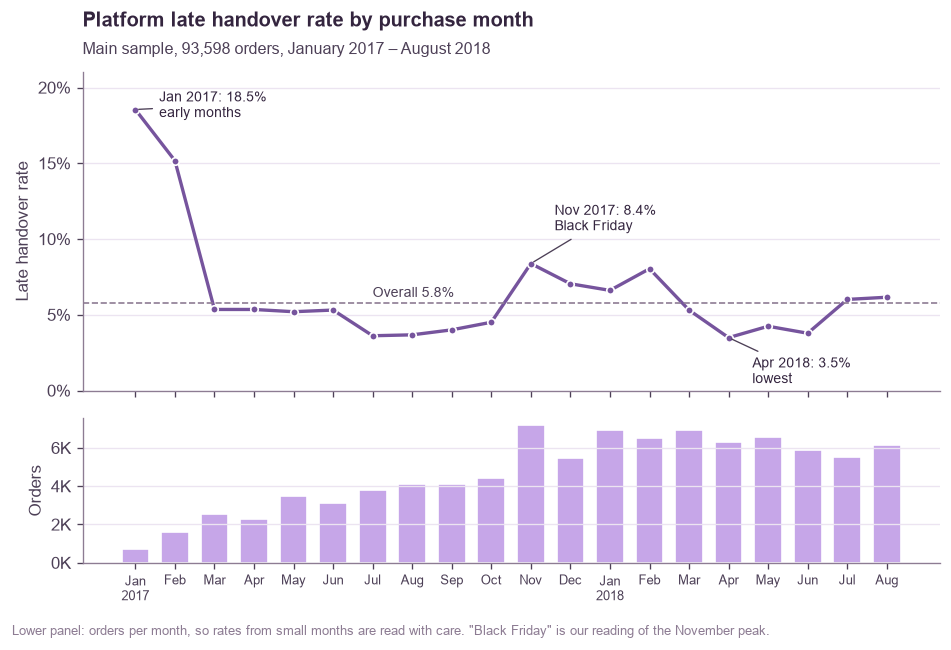

In [3]:
positions = range(len(months))
periods = pd.PeriodIndex(months["order_purchase_month"], freq="M")
tick_labels = [p.strftime("%b\n%Y") if p.month == 1 else p.strftime("%b") for p in periods]

fig, (rate_ax, orders_ax) = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True,
                                         gridspec_kw={"height_ratios": [2.2, 1]})
rate_ax.plot(positions, months["late_rate"], color=PURPLE, linewidth=2,
             marker="o", markersize=4.5, markeredgecolor="white", markeredgewidth=1)
rate_ax.axhline(platform_rate, color=FAINT, linestyle="--", linewidth=1)
rate_ax.text(6, platform_rate + 0.004, f"Overall {platform_rate:.1%}", color=MUTED, fontsize=8.5)  # in a gap of the line
for month, text, offset in [("2017-01", "early months", -0.005), ("2017-11", "Black Friday", 0.022),
                            ("2018-04", "lowest", -0.03)]:
    i = months.index[months["order_purchase_month"].eq(month)][0]
    rate = months.loc[i, "late_rate"]
    rate_ax.annotate(f"{periods[i].strftime('%b %Y')}: {rate:.1%}\n{text}", (i, rate),
                     xytext=(i + 0.6, rate + offset), fontsize=8.5, color=INK,
                     arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
rate_ax.yaxis.set_major_locator(MultipleLocator(0.05))
rate_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
rate_ax.set_ylim(0, 0.21)
rate_ax.set_ylabel("Late handover rate")
rate_ax.grid(axis="x", visible=False)
add_titles(rate_ax, "Platform late handover rate by purchase month",
           f"Main sample, {total_orders:,} orders, January 2017 – August 2018")

orders_ax.bar(positions, months["orders"], color=LAVENDER, edgecolor="white", linewidth=1, width=0.7)
orders_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f}K"))
orders_ax.set_ylabel("Orders")
orders_ax.grid(axis="x", visible=False)
orders_ax.set_xticks(list(positions))
orders_ax.set_xticklabels(tick_labels, fontsize=8)

finish(fig, "slide03_monthly_trend.png",
       "Lower panel: orders per month, so rates from small months are read with care. "
       "\"Black Friday\" is our reading of the November peak.")

## 3. Slide 4 · Concentration of late handovers

Same chart as `q1_02a_pareto_curve.png`: sellers ranked from most to fewest late handovers, against the
cumulative share of all late handovers.

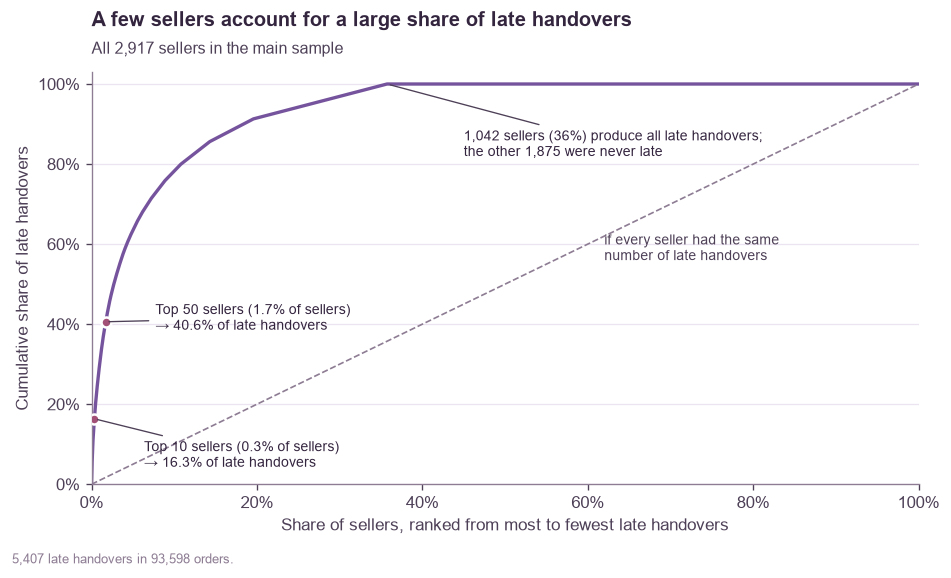

In [4]:
ever_late_sellers = ranked.loc[ranked["late_orders"].gt(0)]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(np.r_[0, ever_late_sellers["cumulative_share_of_sellers"], 1],
        np.r_[0, ever_late_sellers["cumulative_share_of_late_orders"], 1], color=PURPLE, linewidth=2)
ax.plot([0, 1], [0, 1], color=FAINT, linewidth=1, linestyle="--")
ax.text(0.62, 0.56, "if every seller had the same\nnumber of late handovers", color=MUTED, fontsize=8.5)

for n, offset in [(10, -0.12), (50, -0.02)]:
    x, y = ranked.loc[n - 1, ["cumulative_share_of_sellers", "cumulative_share_of_late_orders"]]
    ax.scatter([x], [y], s=36, color=BERRY, zorder=3, edgecolor="white", linewidth=1.5)
    ax.annotate(f"Top {n} sellers ({x:.1%} of sellers)\n→ {y:.1%} of late handovers", (x, y),
                xytext=(x + 0.06, y + offset), fontsize=8.5, color=INK,
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

x = ever_late / len(sellers)
ax.annotate(f"{ever_late:,} sellers ({x:.0%}) produce all late handovers;\n"
            f"the other {len(sellers) - ever_late:,} were never late", (x, 1), xytext=(0.45, 0.82),
            fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Share of sellers, ranked from most to fewest late handovers")
ax.set_ylabel("Cumulative share of late handovers")
add_titles(ax, "A few sellers account for a large share of late handovers",
           f"All {len(sellers):,} sellers in the main sample")
finish(fig, "slide04_pareto_curve.png", f"{total_late:,} late handovers in {total_orders:,} orders.")

## 4. Slide 5 · Why a minimum-order threshold is needed

Same chart as `q1_04_funnel.png`: every seller's late handover rate against its order volume. Sellers with
the same order volume are spread sideways slightly (as in `02`); this does not change their late rate.

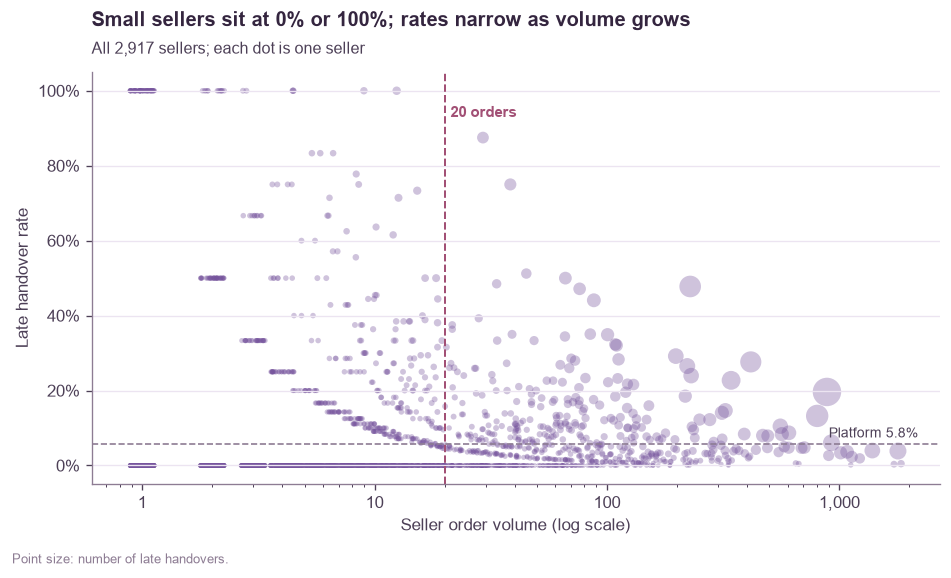

In [5]:
rng = np.random.default_rng(0)   # same seed and spread as in 02_descriptive_analysis
x = sellers["order_volume"] * np.exp(rng.uniform(-0.12, 0.12, len(sellers)))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(x, sellers["late_rate"], s=8 + sellers["late_orders"] * 1.5, alpha=0.35, color=PURPLE, edgecolor="none")
ax.axvline(MIN_ORDERS, color=BERRY, linestyle="--", linewidth=1.2)
ax.text(MIN_ORDERS * 1.06, 0.93, f"{MIN_ORDERS} orders", color=BERRY, fontsize=9, fontweight="bold")
ax.axhline(platform_rate, color=FAINT, linestyle="--", linewidth=1)
ax.text(900, platform_rate + 0.017, f"Platform {platform_rate:.1%}", color=MUTED, fontsize=8.5)

ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))  # 1, 10, 100 instead of 10^0, 10^1
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Seller order volume (log scale)")
ax.set_ylabel("Late handover rate")
add_titles(ax, "Small sellers sit at 0% or 100%; rates narrow as volume grows",
           f"All {len(sellers):,} sellers; each dot is one seller")
finish(fig, "slide05_funnel.png", "Point size: number of late handovers.")

## 5. Slide 5 · Late handover rates of sellers with at least 20 orders

Same chart as `q1_03b_late_rate_bands.png`. Light bars are at or below the platform rate, dark bars above it;
the shares are of all late handovers in the main sample.

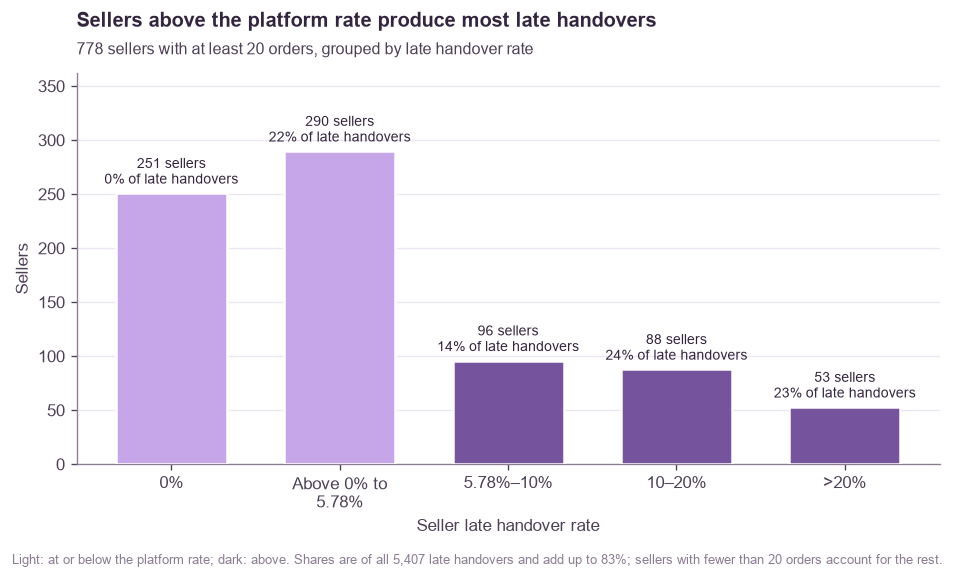

In [6]:
colors = [LAVENDER, LAVENDER, PURPLE, PURPLE, PURPLE]

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(late_rate_bands.index.astype(str), late_rate_bands["sellers"], color=colors,
              edgecolor="white", linewidth=1.5, width=0.66, zorder=3)
for bar, row in zip(bars, late_rate_bands.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, row.sellers + 5,
            f"{row.sellers} sellers\n{row.share_of_late_orders:.0%} of late handovers",
            ha="center", va="bottom", fontsize=8.5, color=INK)

ax.set_ylim(0, late_rate_bands["sellers"].max() * 1.25)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Seller late handover rate")
ax.set_ylabel("Sellers")
add_titles(ax, "Sellers above the platform rate produce most late handovers",
           f"{len(large_sellers):,} sellers with at least {MIN_ORDERS} orders, grouped by late handover rate")
finish(fig, "slide05_late_rate_bands.png",
       f"Light: at or below the platform rate; dark: above. Shares are of all {total_late:,} late handovers and add "
       f"up to {late_rate_bands['share_of_late_orders'].sum():.0%}; sellers with fewer than {MIN_ORDERS} orders "
       "account for the rest.")

## 6. Slide 6 · Choosing the number of tiers

Same chart as `q2_01_choose_k.png`. The table is rebuilt with the shared functions in `q2_tiers.py` and the
same steps and seed as `03_q2` (Section 3). The no-groups baseline shuffles late rates at random, so its
average can differ in the third decimal between package versions; the pattern (real silhouette below the
baseline at every k) does not change.

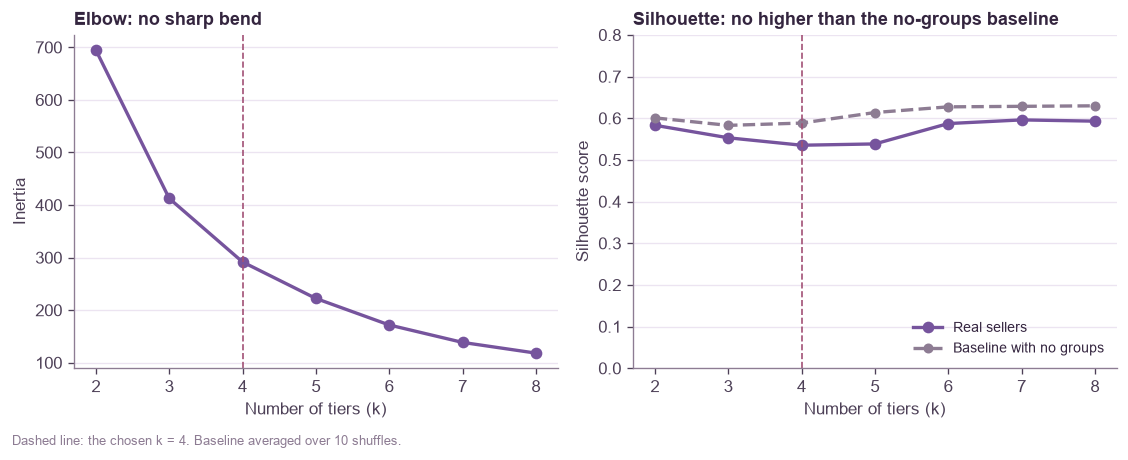

,k,inertia,silhouette,baseline_no_groups
0,2,694.835,0.583,0.601
1,3,412.607,0.553,0.583
2,4,291.715,0.535,0.588
3,5,222.274,0.538,0.614
4,6,171.797,0.587,0.627
5,7,138.643,0.596,0.629
6,8,118.280,0.593,0.630


In [7]:
eligible = sellers[sellers["order_volume"] >= MIN_ORDERS].reset_index(drop=True)
X = make_features(eligible)


def baseline_silhouette(eligible, k, rng):
    # Silhouette for sellers whose late rates were randomly reassigned (no real groups); copied from 03_q2
    volume = eligible["order_volume"].to_numpy()
    late = np.round(rng.permutation(eligible["late_rate"].to_numpy()) * volume)
    fake = pd.DataFrame({"late_rate": late / volume, "late_orders": late})
    Z = make_features(fake)
    return silhouette_score(Z, fit_kmeans(Z, k).labels_)


rng = np.random.default_rng(RANDOM_STATE)
k_rows = []
for k in K_RANGE:
    model = fit_kmeans(X, k)
    k_rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X, model.labels_),
                   "baseline_no_groups": np.mean([baseline_silhouette(eligible, k, rng) for _ in range(10)])})
k_table = pd.DataFrame(k_rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
ax1.plot(k_table["k"], k_table["inertia"], color=PURPLE, linewidth=2, marker="o", markersize=6)
ax1.set_ylabel("Inertia")
ax2.plot(k_table["k"], k_table["silhouette"], color=PURPLE, linewidth=2, marker="o", markersize=6,
         label="Real sellers")
ax2.plot(k_table["k"], k_table["baseline_no_groups"], color=FAINT, linestyle="--", linewidth=2,
         marker="o", markersize=5, label="Baseline with no groups")
ax2.set_ylabel("Silhouette score")
ax2.set_ylim(0, 0.8)
ax2.legend(frameon=False, fontsize=8.5, loc="lower right")
for ax, title in [(ax1, "Elbow: no sharp bend"), (ax2, "Silhouette: no higher than the no-groups baseline")]:
    ax.axvline(CHOSEN_K, color=BERRY, linestyle="--", linewidth=1)
    ax.set_xlabel("Number of tiers (k)")
    ax.set_xticks(list(K_RANGE))
    ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold", color=INK)
finish(fig, "slide06_choose_k.png", f"Dashed line: the chosen k = {CHOSEN_K}. Baseline averaged over 10 shuffles.")
k_table.round(3)

## 7. Slide 7 · Four tiers along one lateness scale

The Q2 tier chart (from `q2_02_tiers_plot.py`), in the presentation colours. It reads the saved tiers, so it
does not rerun K-means. Late-handover counts are whole numbers, so many sellers share one position; each dot
is moved sideways by a random but seeded amount inside its own count, so stacked sellers stay visible.

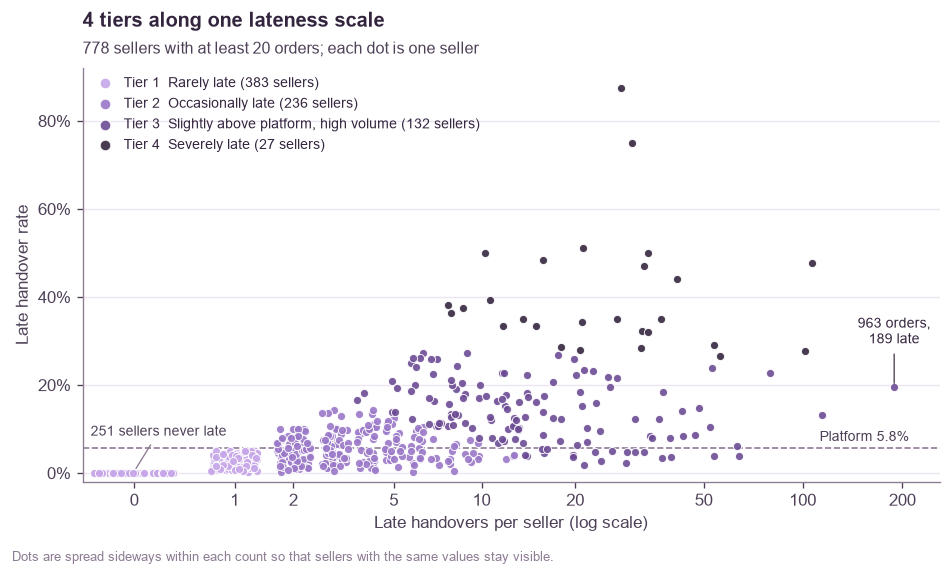

In [8]:
# Late-handover counts are whole numbers, so many sellers share one x position. Each dot is moved
# sideways by a random amount inside its own count (in log space) so that stacked sellers stay visible.
rng = np.random.default_rng(RANDOM_STATE)
x_pos = tiers["late_orders"] + 1
half_gap = 0.4 * np.log((x_pos + 1) / x_pos)
x_plot = x_pos * np.exp(rng.uniform(-1, 1, len(tiers)) * half_gap)

fig, ax = plt.subplots(figsize=(8, 4.8))
for tier in sorted(tiers["tier"].unique()):
    in_tier = tiers["tier"] == tier
    ax.scatter(
        x_plot[in_tier], tiers.loc[in_tier, "late_rate"], s=24, alpha=0.9, color=TIER_COLORS[tier],
        edgecolors="white", linewidths=0.6, zorder=3,
        label=f"Tier {tier}  {TIER_NAMES[tier]} ({in_tier.sum()} sellers)",
    )

# Platform late rate as a reference line
ax.axhline(platform_rate, color=FAINT, linestyle="--", linewidth=1, zorder=2)
ax.annotate(f"Platform {platform_rate:.1%}", (210, platform_rate), xytext=(0, 4),
            textcoords="offset points", ha="right", fontsize=8.5, color=MUTED)

# Label the sellers stacked at zero and the seller with the most late handovers
never_late = (tiers["late_orders"] == 0).sum()
ax.annotate(f"{never_late} sellers never late", (1, 0.004), xytext=(0.74, 0.085), ha="left", fontsize=8.5,
            color=MUTED, arrowprops=dict(arrowstyle="-", color=FAINT, lw=0.8))
top = tiers.loc[tiers["late_orders"].idxmax()]
ax.annotate(f"{int(top['order_volume'])} orders,\n{int(top['late_orders'])} late",
            (top["late_orders"] + 1, top["late_rate"]), xytext=(0, 26), textcoords="offset points",
            ha="center", fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

# Log x axis labelled with the real counts (x is late handovers + 1, so 0 can be shown)
ax.set_xscale("log")
ticks = [0, 1, 2, 5, 10, 20, 50, 100, 200]
ax.set_xticks([t + 1 for t in ticks])
ax.set_xticklabels([str(t) for t in ticks])
ax.minorticks_off()
ax.set_xlim(0.7, 260)
ax.set_ylim(-0.02, 0.92)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Late handovers per seller (log scale)")
ax.set_ylabel("Late handover rate")

# Title, subtitle, legend and footnote
ax.text(0, 1.1, f"{tiers['tier'].nunique()} tiers along one lateness scale", transform=ax.transAxes,
        fontsize=12, fontweight="bold", color=INK)
ax.text(0, 1.035, f"{len(tiers)} sellers with at least {MIN_ORDERS} orders; each dot is one seller",
        transform=ax.transAxes, fontsize=9.5, color=MUTED)
ax.legend(frameon=False, fontsize=8.5, loc="upper left", handletextpad=0.3, markerscale=1.3, borderaxespad=0.2)
fig.text(0.015, 0.01, "Dots are spread sideways within each count so that sellers with the same values stay visible.",
         fontsize=7.5, color=FAINT)

fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "slide07_tiers.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

**How to read the slide figures.** Each one shows the same numbers as the original figure named in its
section; only colours, fonts, titles and labels differ. On slide 7, dots further right have more late
handovers and dots higher up are late more often; the tiers follow one lateness scale rather than forming
separate clouds.